# M1 Validation: LERP Latent Interpolation
End-to-end M1 validation with A3 latent injection.

In [1]:
from helpers.runtime.utility import print_runtime_paths
print_runtime_paths()

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.11 (you have 3.13.11)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
W0418 22:08:24.928000 29052 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


CWD: c:\Users\David\Desktop\thesis\NeLs\project\jupyter
PYTHONPATH env: C:\Users\David\Desktop\thesis\NeLs\project\python
C:\Users\David\Desktop\thesis\NeLs\project\python


In [2]:
from helpers.runtime.utility import print_cuda_environment
print_cuda_environment()

Python: c:\Users\David\Desktop\thesis\NeLs\.venv\Scripts\python.exe
Torch version: 2.11.0+cu130
Torch CUDA runtime: 13.0
CUDA build available: True
CUDA useable: True
CUDA device count: 1
DEVICE in .env (user specified): cuda
CUDA DEVICES:
- GPU 0: NVIDIA GeForce RTX 2070


In [1]:
from pathlib import Path
import time
import torch
from IPython.display import display
from helpers.methods.access import infer_latent_shape
from helpers.methods.navigation import lerp_latents
from helpers.runtime.pipeline import default_torch_dtype_for_device, load_flux_pipeline, resolve_runtime_device
from helpers.runtime.sampling import generate_with_prompt
from helpers.runtime.utility import flush_namespace, seed_latent

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.11 (you have 3.13.11)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
W0419 00:04:37.128000 15148 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Before flush: allocated=0.00 GB, reserved=0.00 GB, peak_allocated=0.00 GB
After flush: allocated=0.00 GB, reserved=0.00 GB, peak_allocated=0.00 GB


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Enabled layerwise casting on transformer (storage=torch.float8_e4m3fn, compute=torch.float16)


The module 'Flux2Transformer2DModel' is group offloaded and moving it to cuda via `.to()` is not supported.


Enabled group offloading for text_encoder (offload_type=block_level)
Enabled group offloading for vae (offload_type=leaf_level)
Loaded pipeline with transformer group offload enabled (use_stream=True, low_cpu_mem_usage=False)
Enabled VAE slicing via vae.enable_slicing()
Enabled VAE tiling via vae.enable_tiling()
Enabled channels-last memory format on vae
Skipping xFormers attention: No operator found for `memory_efficient_attention_forward` with inputs:
     query       : shape=(1, 2, 1, 40) (torch.float32)
     key         : shape=(1, 2, 1, 40) (torch.float32)
     value       : shape=(1, 2, 1, 40) (torch.float32)
     attn_bias   : <class 'NoneType'>
     p           : 0.0
`fa3F@0.0.0` is not supported because:
    xFormers wasn't build with CUDA support
    requires device with capability >= (8, 0) but your GPU has capability (7, 5) (too old)
    dtype=torch.float32 (supported: {torch.float16, torch.bfloat16})
    operator wasn't built - see `python -m xformers.info` for more info
`

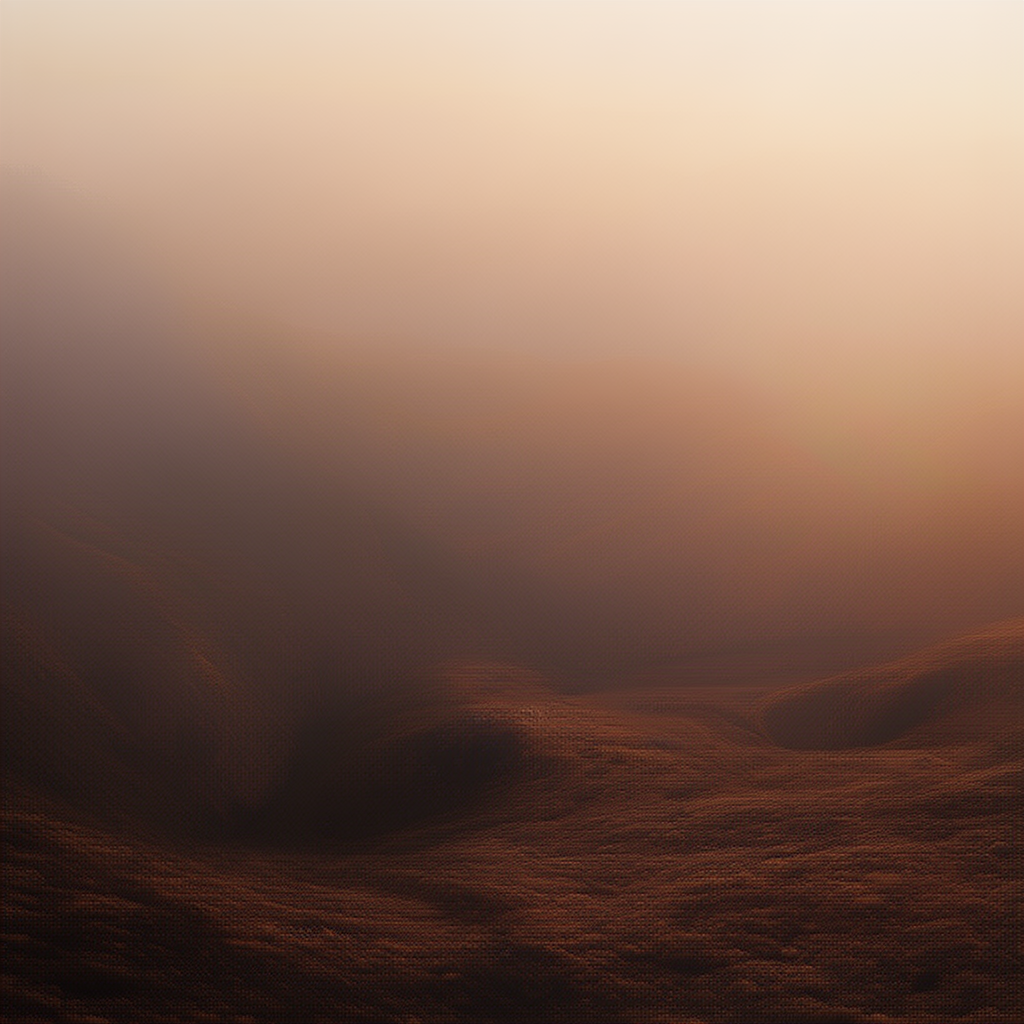

Before flush: allocated=0.01 GB, reserved=10.43 GB, peak_allocated=7.71 GB
After flush: allocated=0.01 GB, reserved=0.02 GB, peak_allocated=0.01 GB


KeyboardInterrupt: 

In [2]:
# Cleanup before loading a new model.
flush_namespace(
    globals(),
    "pipe",
    "out",
    "image",
    "latent",
    "start",
    "end",
    verbose=True,
)

output_dir = Path("../python/examples/navigation/outputs/m1_lerp_notebook").resolve()
output_dir.mkdir(parents=True, exist_ok=True)

device = resolve_runtime_device()
dtype = default_torch_dtype_for_device(torch.float16, device)
try:
    pipe = load_flux_pipeline(
        torch_dtype=dtype,
        device=device,
        offload_mode="group",
        group_use_stream=True,
        group_low_cpu_mem_usage=False,
        enable_text_encoder_group_offload=True,
        text_encoder_group_offload_type="block_level",
        text_encoder_num_blocks_per_group=1,
        enable_vae_group_offload=True,
        vae_group_offload_type="leaf_level",
        vae_num_blocks_per_group=2,
        enable_vae_slicing=True,
        enable_vae_tiling=True,
        enable_layerwise_casting=True,
        layerwise_storage_dtype="float8_e4m3fn",
        layerwise_compute_dtype=dtype,
        enable_channels_last=True,
        enable_xformers_attention=True,
        enable_torch_compile=False,
    )

    shape = infer_latent_shape(height=1024, width=1024)
    start = seed_latent(11, shape, dtype)
    end = seed_latent(77, shape, dtype)

    # Keep smoke test short while exercising the full runtime path.
    for alpha in [0.0, 0.5, 1.0]:
        latent = lerp_latents(start, end, alpha)

        t0 = time.perf_counter()
        with torch.inference_mode():
            out = generate_with_prompt(
                pipe=pipe,
                prompt="a high-detail mountain valley at sunrise",
                seed=123,
                latents=latent,
                num_inference_steps=4, # Set low for smoke test; increase for better quality.
                guidance_scale=0.0,
            )
        t1 = time.perf_counter()
        image = out.images[0]

        path = output_dir / f"m1_lerp_alpha_{alpha:.2f}_{(t1 - t0):.2f}.png"
        image.save(path)

        print(f"alpha={alpha:.2f} in {(t1 - t0):.2f} s -> {path}")
        display(image)
finally:
    flush_namespace(
        globals(),
        "pipe",
        "out",
        "image",
        "latent",
        "start",
        "end",
        verbose=True,
    )